In [1]:
import torch
import torch.nn as nn
import torch.optim as optim

from torchvision import transforms, datasets

from torch.utils.data import DataLoader, TensorDataset

from transformers import CLIPTokenizer, CLIPTextModel

import matplotlib.pyplot as plt

import math

In [2]:
# For GPU computation

device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(device)

cuda


In [3]:
# Loading the Oxford Flowers-102 dataset

img_size = 64

data_transform = transforms.Compose([
    transforms.Resize((img_size, img_size)),                          # All imgs have different img_size, so we make all img of same size
    transforms.ToTensor(),
    transforms.Normalize(mean = [0.5]*3, std = [0.5]*3)   # Scales image pixel values from [0.0, 1.0] to [-1.0, 1.0]
])

train_data = datasets.Flowers102(root = './data', split = 'train', download = True, transform = data_transform)    # 1020 imgs
test_data = datasets.Flowers102(root = './data', split = 'test', download = True, transform = data_transform)      # 6149 imgs
val_data = datasets.Flowers102(root = './data', split = 'val', download = True, transform = data_transform)        # 1020 imgs

# Since training data is very small(1020 imgs), we add training, testing, validation together to make training data
full_dataset = torch.utils.data.ConcatDataset([train_data, test_data, val_data])

In [4]:
# Lable mapping of the dataset

label_val = {0: "pink primrose", 1: "hard-leaved pocket orchid", 2: "canterbury bells", 3: "sweet pea", 4: "english marigold", 5: "tiger lily", 6: "moon orchid", 7: "bird of paradise", 8: "monkshood", 9: "globe thistle", 10: "snapdragon", 11: "colt's foot", 12: "king protea", 13: "spear thistle", 14: "yellow iris", 15: "globe-flower", 16: "purple coneflower", 17: "peruvian lily", 18: "balloon flower", 19: "giant white arum lily", 20: "fire lily", 21: "pincushion flower", 22: "fritillary", 23: "red ginger", 24: "grape hyacinth", 25: "corn poppy", 26: "prince of wales feathers", 27: "stemless gentian", 28: "artichoke", 29: "sweet william", 30: "carnation", 31: "garden phlox", 32: "love in the mist", 33: "mexican aster", 34: "alpine sea holly", 35: "ruby-lipped cattleya", 36: "cape flower", 37: "great masterwort", 38: "siam tulip", 39: "lenten rose", 40: "barbeton daisy", 41: "daffodil", 42: "sword lily", 43: "poinsettia", 44: "bolero deep blue", 45: "wallflower", 46: "marigold", 47: "buttercup", 48: "oxeye daisy", 49: "common dandelion", 50: "petunia", 51: "wild pansy", 52: "primula", 53: "sunflower", 54: "pelargonium", 55: "bishop of llandaff", 56: "gaura", 57: "geranium", 58: "orange dahlia", 59: "pink-yellow dahlia", 60: "cautleya spicata", 61: "japanese anemone", 62: "black-eyed susan", 63: "silverbush", 64: "californian poppy", 65: "osteospermum", 66: "spring crocus", 67: "bearded iris", 68: "windflower", 69: "tree poppy", 70: "gazania", 71: "azalea", 72: "water lily", 73: "rose", 74: "thorn apple", 75: "morning glory", 76: "passion flower", 77: "lotus", 78: "toad lily", 79: "anthurium", 80: "frangipani", 81: "clematis", 82: "hibiscus", 83: "columbine", 84: "desert-rose", 85: "tree mallow", 86: "magnolia", 87: "cyclamen", 88: "watercress", 89: "canna lily", 90: "hippeastrum", 91: "bee balm", 92: "ball moss", 93: "foxglove", 94: "bougainvillea", 95: "camellia", 96: "mallow", 97: "mexican petunia", 98: "bromelia", 99: "blanket flower", 100: "trumpet creeper", 101: "blackberry lily"}

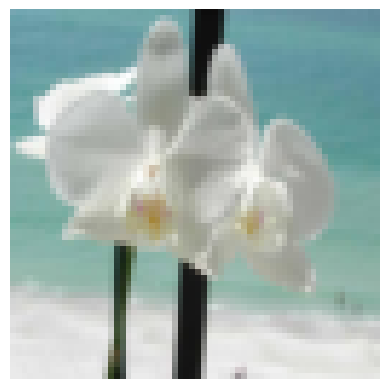

torch.Size([3, 64, 64]) 
Name of the flower:  moon orchid
Total images in dataset:  8189


In [5]:
# Visualizing the data

sample_image, label = full_dataset[64]

# Denormalize the image for correct display
image_to_display = (sample_image * 0.5) + 0.5       # Reverse the normalization: (tensor * std) + mean, because matplotlib.imshow expects
                                                    # pixel values to be in the [0.0, 1.0] range for floating-point data

plt.imshow(image_to_display.permute(1, 2, 0))       # (C, H, W) --> (H, W, C), ex: (3, 128, 128) --> (128, 128, 3)
plt.axis('off')
plt.show()

print(sample_image.size(), '\nName of the flower: ', label_val[label])
print('Total images in dataset: ', len(full_dataset))

In [6]:
# DataLoader

Batch_Size = 32

train_loader = DataLoader(full_dataset, batch_size = Batch_Size, shuffle = True)

In [7]:
# VAE

class VAE(nn.Module):
  def __init__(self):
    super().__init__()

    # Encode
    self.en_c1 = nn.Conv2d(3, 6, 3, stride = 2, padding = 1)         # o/p: [6, 32, 32] ([3, 64, 64] --> [6, 32, 32])
    self.en_gn1 = nn.GroupNorm(2, 6)
    self.en_c2 = nn.Conv2d(6, 12, 3, stride = 2, padding = 1)        # o/p: [12, 16, 16]
    self.en_gn2 = nn.GroupNorm(4, 12)
    self.en_mu = nn.Conv2d(12, 24, 3, stride = 2, padding = 1)       # o/p: [24, 8, 8]
    self.en_logvar = nn.Conv2d(12, 24, 3, stride = 2, padding = 1)   # o/p: [24, 8, 8]

    # Decode
    self.de_c1 = nn.ConvTranspose2d(24, 12, 4, stride = 2, padding = 1)  # o/p: [12, 16, 16] ([24, 8, 8] --> [12, 16, 16])
    self.de_gn1 = nn.GroupNorm(4, 12)
    self.de_c2 = nn.ConvTranspose2d(12, 6, 4, stride = 2, padding = 1)   # o/p: [6, 32, 32]
    self.de_gn2 = nn.GroupNorm(2, 6)
    self.de_c3 = nn.ConvTranspose2d(6, 3, 4, stride = 2, padding = 1)    # o/p: [3, 64, 64]

    # Activation function
    self.silu = nn.SiLU()
    self.tanh = nn.Tanh()

  # Encoder
  def encoder(self, x):
    x = self.silu(self.en_gn1(self.en_c1(x)))
    x = self.silu(self.en_gn2(self.en_c2(x)))
    mu = self.en_mu(x)
    logvar = self.en_logvar(x)
    return mu, logvar

  # Reparameterization
  def reparameterize(self, mu, logvar):
    std = torch.exp(0.5*logvar)                               # Standard deviation is sigma, while sigma square is the variance
    eps = torch.randn_like(std)
    z = mu + eps*std
    return z

  # Decoder
  def decoder(self, z):
    z = self.silu(self.de_gn1(self.de_c1(z)))
    z = self.silu(self.de_gn2(self.de_c2(z)))
    out = self.tanh(self.de_c3(z))
    return out

  # Forward
  def forward(self, x):
    mu, logvar = self.encoder(x)
    z = self.reparameterize(mu, logvar)
    x_recon = self.decoder(z)
    return x_recon, mu, logvar

In [8]:
# Defining Loss function of VAE

def VAE_loss_fn(x, x_recon, mu, logvar):

  reconstruction_loss = nn.functional.mse_loss(x_recon, x, reduction = 'sum')

  variance = torch.exp(logvar)
  kl_loss = -0.5 * torch.sum(1 + logvar - mu.pow(2) - variance)

  total_loss = reconstruction_loss + kl_loss

  return total_loss

In [9]:
# Initializing the model, and defining the optimizer

VAE_model = VAE()
VAE_model = VAE_model.to(device)

optimizer = optim.Adam(VAE_model.parameters(), lr = 1e-3)

In [10]:
# Training

Epoch = 30

for epoch in range(Epoch):
  total_epoch_loss = 0                           # Reseting total_epoch_loss for each epoch

  for x, _ in train_loader:

    x = x.to(device)

    optimizer.zero_grad()
    x_recon, mu, logvar = VAE_model(x)

    loss = VAE_loss_fn(x, x_recon, mu, logvar)
    loss.backward()
    optimizer.step()

    total_epoch_loss += loss.item()            # Accumulating batch loss

  # Calculating average epoch loss
  avg_epoch_loss = total_epoch_loss / len(train_loader)

  print(f'Epoch [{epoch+1}/{Epoch}]: Loss: {avg_epoch_loss:.4f}')

Epoch [1/30]: Loss: 66569.7028
Epoch [2/30]: Loss: 37465.3122
Epoch [3/30]: Loss: 32470.7955
Epoch [4/30]: Loss: 30310.5269
Epoch [5/30]: Loss: 29560.6005
Epoch [6/30]: Loss: 29063.9310
Epoch [7/30]: Loss: 28652.8772
Epoch [8/30]: Loss: 28141.2660
Epoch [9/30]: Loss: 27488.9662
Epoch [10/30]: Loss: 27087.1164
Epoch [11/30]: Loss: 26889.8306
Epoch [12/30]: Loss: 26690.6138
Epoch [13/30]: Loss: 26616.8563
Epoch [14/30]: Loss: 26527.5855
Epoch [15/30]: Loss: 26397.2154
Epoch [16/30]: Loss: 26314.6670
Epoch [17/30]: Loss: 26277.5795
Epoch [18/30]: Loss: 26226.8886
Epoch [19/30]: Loss: 26184.9049
Epoch [20/30]: Loss: 26112.3190
Epoch [21/30]: Loss: 26100.7794
Epoch [22/30]: Loss: 26016.6508
Epoch [23/30]: Loss: 26001.9703
Epoch [24/30]: Loss: 25964.3385
Epoch [25/30]: Loss: 25940.0033
Epoch [26/30]: Loss: 25894.6373
Epoch [27/30]: Loss: 25873.9564
Epoch [28/30]: Loss: 25843.4187
Epoch [29/30]: Loss: 25848.5826
Epoch [30/30]: Loss: 25814.9524


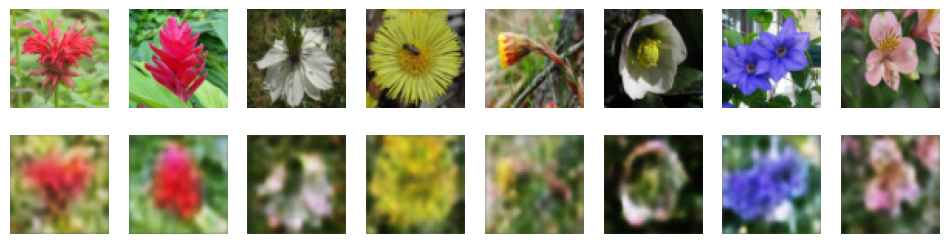

In [11]:
# Generating samples from trained VAE model (on the trained data)

VAE_model.eval()

with torch.no_grad():

  x, _ = next(iter(train_loader))
  x = x.to(device)

  x_recon, _, _ = VAE_model.forward(x)

  n = 8                                           # n --> Number of images to plot
  plt.figure(figsize = (12, 3))

  for i in range(n):
    # Denormalize original image for display
    original_img_display = (x[i] * 0.5) + 0.5

    # Original image
    plt.subplot(2, n, i+1)
    plt.imshow(original_img_display.cpu().permute(1, 2, 0))
    plt.axis('off')

    # Denormalize reconstructed image for display
    reconstructed_img_display = (x_recon[i] * 0.5) + 0.5

    # Reconstructed image
    plt.subplot(2, n, i+1+n)
    plt.imshow(reconstructed_img_display.cpu().permute(1, 2, 0))
    plt.axis('off')

  plt.show()

#  Downloding Pre-trained Text Encoder

In [12]:
# CLIP's Text Encoder

model = 'openai/clip-vit-base-patch32'

tokenizer = CLIPTokenizer.from_pretrained(model)

text_encoder = CLIPTextModel.from_pretrained(model)

tokenizer_config.json:   0%|          | 0.00/592 [00:00<?, ?B/s]

vocab.json:   0%|          | 0.00/862k [00:00<?, ?B/s]

merges.txt:   0%|          | 0.00/525k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/2.22M [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/389 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/4.19k [00:00<?, ?B/s]

pytorch_model.bin: reconstructing file:   0%|          |  0.00B /  605MB            

pytorch_model.bin: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/196 [00:00<?, ?it/s]

[transformers] CLIPTextModel LOAD REPORT from: openai/clip-vit-base-patch32
Key                                                            | Status     |  | 
---------------------------------------------------------------+------------+--+-
vision_model.encoder.layers.{0...11}.mlp.fc2.weight            | UNEXPECTED |  | 
vision_model.encoder.layers.{0...11}.self_attn.q_proj.weight   | UNEXPECTED |  | 
vision_model.encoder.layers.{0...11}.layer_norm2.weight        | UNEXPECTED |  | 
vision_model.encoder.layers.{0...11}.mlp.fc1.bias              | UNEXPECTED |  | 
vision_model.encoder.layers.{0...11}.self_attn.out_proj.weight | UNEXPECTED |  | 
vision_model.encoder.layers.{0...11}.self_attn.v_proj.weight   | UNEXPECTED |  | 
vision_model.encoder.layers.{0...11}.self_attn.q_proj.bias     | UNEXPECTED |  | 
vision_model.encoder.layers.{0...11}.self_attn.v_proj.bias     | UNEXPECTED |  | 
vision_model.encoder.layers.{0...11}.layer_norm2.bias          | UNEXPECTED |  | 
vision_model.encoder.l

# Creating Latents of the Dataset

In [13]:
# Text Embedding of the label

def text_embedding(label):

  label = label.tolist()                                                # Converting 0-d CUDA tensors to list

  label_prompt = []

  # Converting Label to Label prompt
  for i in label:
    name = label_val[i]
    if i % 2 == 0:
      name = 'a photo of ' + name
    else:
      name = 'This flower is called as ' + name
    label_prompt.append(name)

  # Tokenizing the label prompt
  token = tokenizer(
      label_prompt,
      padding = 'max_length',
      max_length = 32,
      truncation = True,
      return_tensors = 'pt'
  )
  token.to(device)

  # Creating embedding of Label prompt
  with torch.no_grad():
    text_emb = text_encoder(input_ids = token['input_ids'], attention_mask = token['attention_mask'])   # Or we can simply go with: text_encoder(**token)

  return text_emb.last_hidden_state.cpu()             # [B, 32, d_txt]

In [15]:
# Creating a Latent Dataset of Flower102

VAE_model = VAE_model.to(device)
text_encoder = text_encoder.to(device)

VAE_model.eval()
text_encoder.eval()

all_mu = []
all_label = []

with torch.no_grad():                                           # Freezing VAE and Text encoder

    for x, label in train_loader:

        x = x.to(device)
        label = label.to(device)

        # Encoder's mu
        mu, logvar = VAE_model.encoder(x)
        all_mu.append(mu.cpu())

        # Label embedding
        text_emd = text_embedding(label)
        all_label.append(text_emd)

# Latent dataset with mean (mu) & label embedding
all_latents = torch.cat(all_mu, dim = 0)                 # [N, 24, 8, 8]
all_text = torch.cat(all_label, dim = 0)              # [N, 32, 768]

latent_scale = all_latents.std().item()                  # It is standard deviation of all numbers in the all_latents

latent_dataset = TensorDataset(all_latents / latent_scale, all_text)

In [16]:
# Creating Latent_loader

latent_loader = DataLoader(latent_dataset, batch_size = 64, shuffle = True)

# sanity check
z_batch, embding_batch= next(iter(latent_loader))
print(z_batch.shape)
print(embding_batch.shape)

torch.Size([64, 24, 8, 8])
torch.Size([64, 32, 512])


# DDIM in Latent space

In [17]:
# Noise schedule

T = 1000
beta = torch.linspace(1e-4, 0.02, T, device = device)
alpha = 1 - beta
alpha_bar = torch.cumprod(alpha, dim = 0)

In [18]:
# Forward diffusion

def forward_diffusion(z_0, T):

  noise = torch.randn_like(z_0)

  alpha_bar_T = alpha_bar[T].view(-1, 1, 1, 1)   # (batch_size, 1, 1, 1): to match the (B, C, H, W) of z_0 and noise

  z_t = torch.sqrt(alpha_bar_T) * z_0 + torch.sqrt(1 - alpha_bar_T) * noise

  return z_t, noise

In [19]:
# Time Embedding

class Time_embedding(nn.Module):
  def __init__(self, emb_dim):
    super().__init__()

    self.emb_dim = emb_dim

    # MLP
    self.mlp = nn.Sequential(
        nn.Linear(emb_dim, emb_dim),
        nn.SiLU(),
        nn.Linear(emb_dim, emb_dim)
    )

  def forward(self, t):

    emb_dim = self.emb_dim
    half = emb_dim // 2

    freq = torch.exp(-math.log(10000) * 2 * torch.arange(half, device = device) / half)    # The denominator coming to numerator: exp(-log(10000)*2i/d)

    t = t.unsqueeze(-1).float()        # (B,) -> (B, 1)
    freq = freq.unsqueeze(0)           # (half,) -> (1, half)
    args = t * freq                    # (B,1) * (1,half) -> (B, half)

    time_vec = torch.cat([torch.sin(args), torch.cos(args)], dim = -1)

    time_vec = self.mlp(time_vec)

    return time_vec

In [20]:
# Resblock

class Resblock(nn.Module):
  def __init__(self, ch_in, ch_out, emb_dim):                          # emb_dim: is the channels in the Time vector
    super().__init__()

    # Block 1
    self.gn1 = nn.GroupNorm(max(1, ch_in//4), ch_in)
    self.silu1 = nn.SiLU()
    self.conv1 = nn.Conv2d(ch_in, ch_out, 3, padding = 1)

    # Making time_vec's number of channel equal to number of channel in the o/p of conv1, so that we can do element-wise addintion across channel
    self.time_proj = nn.Linear(emb_dim, ch_out)

    # Block 2
    self.gn2 = nn.GroupNorm(max(1, ch_out//4), ch_out)
    self.silu2 = nn.SiLU()
    self.conv2 = nn.Conv2d(ch_out, ch_out, 3, padding = 1)

  def forward(self, x, time_vec):
    x = self.gn1(x)
    x = self.silu1(x)
    x = self.conv1(x)

    # Changing the shape of time_vec
    time_vec = self.time_proj(time_vec)                     # (B, emb_dim) -> (B, C)
    time_vec = time_vec.view(time_vec.shape[0], -1, 1, 1)   # (B, C) -> (B, C, 1, 1)

    # Adding Time vector across the channel
    x = x + time_vec

    x = self.gn2(x)
    x = self.silu2(x)
    x = self.conv2(x)

    return x

In [25]:
# Attention Block

class attn_block(nn.Module):

  def __init__(self, ch_in):                                                     # ch_in: no. of Channels in the image tensor
    super().__init__()

    # Q, H, V of self attention
    self.self_gn = nn.GroupNorm(max(1, ch_in//4), ch_in)
    self.self_q = nn.Conv2d(ch_in, ch_in, 1)
    self.self_k = nn.Conv2d(ch_in, ch_in, 1)
    self.self_v = nn.Conv2d(ch_in, ch_in, 1)

    # Q, K, V of cross attention
    self.text_proj = nn.Linear(512, ch_in)                                        # text_emb = [B, 32, 512] --> [B, 32, C]
    self.cross_q = nn.Linear(ch_in, ch_in)
    self.cross_k = nn.Linear(ch_in, ch_in)
    self.cross_v = nn.Linear(ch_in, ch_in)

    # Linear projection
    self.proj = nn.Conv2d(ch_in, ch_in, 1)



  def forward(self, z, text):                                                    # z: [B, 24, 8, 8] , text_emb = [B, 32, 768]

    B, C, H, W = z.shape                                                         # Here, ch_in = C

    # Self attention
    h = self.self_gn(z)

    self_q = self.self_q(h).reshape(B, C, H*W)
    self_k = self.self_k(h).reshape(B, C, H*W)
    self_v = self.self_v(h).reshape(B, C, H*W)

    self_attn = torch.softmax((self_q.transpose(1,2) @ self_k) / math.sqrt(C), dim = -1)   # [B, H*W, C] @ [B, C, H*W] = [B, H*W, H*W]
    self_attn = self_attn @ self_v.transpose(1,2)                                          # [B, H*W, H*W] @ [B, H*W, C] = [B, H*W, C]


    # Cross Attention
    text = self.text_proj(text)                                                            # [B, 32, 768] --> [B, 32, C]

    # Query comes from self attention, key & value come from text embedding
    cross_q = self.cross_q(self_attn)                                                      # [B, H*W, C]
    cross_k = self.cross_k(text)                                                           # [B, 32, C]
    cross_v = self.cross_v(text)                                                           # [B, 32, C]

    cross_attn = torch.softmax((cross_q @ cross_k.transpose(1,2)) / math.sqrt(C), dim = -1)    # [B, H*W, C] @ [B, C, 32] = [B, H*W, 32]
    cross_attn = cross_attn @ cross_v                                                          # [B, H*W, 32] @ [B, 32, C] = [B, H*W, C]

    # Linear projection
    attn = self_attn + cross_attn                                                          # [B, H*W, C] + [B, H*W, C] = [B, H*W, C] (Element-wise addition)
    attn = attn.transpose(1, 2)                                                            # [B, H*W, C] --> [B, C, H*W]
    attn = attn.reshape(B, C, H, W)                                                        # [B, C, H*W] --> [B, C, H, W]
    attn = self.proj(attn)                                                                 # [B, C, H, W] --> [B, C, H, W]

    return z + attn                                                                        # [B, C, H, W] + [B, C, H, W] = [B, C, H, W]

In [26]:
# U-Net

class Unet(nn.Module):
  def __init__(self):
    super().__init__()

    # Encoder level 1
    self.en_res1 = Resblock(24, 24, 128)
    self.en_res2 = Resblock(24, 48, 128)
    self.en_down1 = nn.Conv2d(48, 48, 3, stride = 2, padding = 1)

    # Bottleneck
    self.b_res1 = Resblock(48, 48, 128)
    self.b_attn = attn_block(48)
    self.b_res2 = Resblock(48, 48, 128)

    # Decoder level 1
    self.de_up1 = nn.ConvTranspose2d(48, 24, 3, stride = 2, padding = 1, output_padding = 1)
    self.de_res1 = Resblock(72, 24, 128)
    self.de_res2 = Resblock(24, 24, 128)

    # Final 3x3 conv layer
    self.out = nn.Conv2d(24, 24, 3, padding = 1)



  def forward(self, z, time_vec, text_emb):     # z: [B, 24, 8, 8] , time_vec: [B, 128] , text_emb: [B, 32, 768]

    skip = []

    # Encoder
    z = self.en_res1(z, time_vec)               # [B, 24, 8, 8] --> [B, 24, 8, 8]
    z = self.en_res2(z, time_vec)               # [B, 24, 8, 8] --> [B, 48, 8, 8]
    skip.append(z)                              # saved skip: [B, 48, 8, 8]
    z = self.en_down1(z)                        # [B, 48, 8, 8] --> [B, 48, 4, 4]

    # Bottleneck
    z = self.b_res1(z, time_vec)                # [B, 48, 4, 4] --> [B, 48, 4, 4]
    z = self.b_attn(z, text_emb)                # [B, 48, 4, 4] + text [B, 32, 768] --> [B, 48, 4, 4]
    z = self.b_res2(z, time_vec)                # [B, 48, 4, 4] --> [B, 48, 4, 4]

    # Decoder
    z = self.de_up1(z)                          # [B, 48, 4, 4] --> [B, 24, 8, 8]
    z = torch.cat([z, skip[0]], dim = 1)        # [B, 24, 8, 8] concat [B, 48, 8, 8] --> [B, 72, 8, 8]
    z = self.de_res1(z, time_vec)               # [B, 72, 8, 8] --> [B, 24, 8, 8]
    z = self.de_res2(z, time_vec)               # [B, 24, 8, 8] --> [B, 24, 8, 8]

    # Final 3x3 conv layer
    z = self.out(z)                             # [B, 24, 8, 8] --> [B, 24, 8, 8] (predicted noise)

    return z

In [27]:
# Initializing the U-Net model, and defining the optimizer

unet = Unet()
unet = unet.to(device)

# Creating time object once, and using this same object every time we need it to make the timestep vector. Because there is mlp in it,
# which gets trained during the training epochs. But if we make the object again  we get a brand new object with freshly randomized
# weights it will not use the trained weights of the mlp that were learned during training. So make 1 object and use it every other
# time you need it.
time_emb_object = Time_embedding(128).to(device)

optimizer = optim.Adam(list(unet.parameters()) + list(time_emb_object.parameters()), lr = 1e-3)

In [28]:
# Training of DDIM

Epoch = 35

for epoch in range(Epoch):
  total_epoch_loss = 0

  for (z, text_emb) in latent_loader:

    z = z.to(device)
    text_emb = text_emb.to(device)

    t = torch.randint(0, T, (z.shape[0],), device=device)     # Gives a 1D tensor of Shape: [Batch_Size], where the values are Random
                                           # integers sampled uniformly from the range [0, T-1]. For eg: If batch size (z.shape[0]) is 4,
                                           # then t = tensor([12, 850, 431,  0], device='cuda')

    # Forward diffusion
    z_t, noise = forward_diffusion(z, t)

    # Time embedding
    time_vec = time_emb_object(t)

    # Using U-Net to predict noise
    noise_pred = unet.forward(z_t, time_vec, text_emb)

    # Loss function
    loss = nn.functional.mse_loss(noise_pred, noise)

    # Backpropagation
    optimizer.zero_grad()
    loss.backward()
    optimizer.step()

    total_epoch_loss += loss.item()

  avg_epoch_loss = total_epoch_loss / len(latent_loader)

  print(f'Epoch [{epoch + 1}/{Epoch}]: Loss: {avg_epoch_loss:.5f}')

Epoch [1/35]: Loss: 0.93292
Epoch [2/35]: Loss: 0.81241
Epoch [3/35]: Loss: 0.73726
Epoch [4/35]: Loss: 0.68487
Epoch [5/35]: Loss: 0.64776
Epoch [6/35]: Loss: 0.61876
Epoch [7/35]: Loss: 0.59980
Epoch [8/35]: Loss: 0.58868
Epoch [9/35]: Loss: 0.57763
Epoch [10/35]: Loss: 0.56045
Epoch [11/35]: Loss: 0.54881
Epoch [12/35]: Loss: 0.54257
Epoch [13/35]: Loss: 0.53927
Epoch [14/35]: Loss: 0.53729
Epoch [15/35]: Loss: 0.53635
Epoch [16/35]: Loss: 0.53534
Epoch [17/35]: Loss: 0.53314
Epoch [18/35]: Loss: 0.53422
Epoch [19/35]: Loss: 0.53308
Epoch [20/35]: Loss: 0.53095
Epoch [21/35]: Loss: 0.53123
Epoch [22/35]: Loss: 0.53089
Epoch [23/35]: Loss: 0.52918
Epoch [24/35]: Loss: 0.52904
Epoch [25/35]: Loss: 0.52886
Epoch [26/35]: Loss: 0.52810
Epoch [27/35]: Loss: 0.52909
Epoch [28/35]: Loss: 0.52757
Epoch [29/35]: Loss: 0.52812
Epoch [30/35]: Loss: 0.52595
Epoch [31/35]: Loss: 0.52616
Epoch [32/35]: Loss: 0.52745
Epoch [33/35]: Loss: 0.52604
Epoch [34/35]: Loss: 0.52607
Epoch [35/35]: Loss: 0.

# Printing the Generated Images from trained VAE and DDIM

In [29]:
# Reverse diffusion using DDIM

@torch.no_grad()

def rev_diff(unet_model, stride, text_emb):

  unet_model.eval()

  z_s = torch.randn((text_emb.shape[0], 24, 8, 8), device = device)  # Pure noise

  eta = 0                                                            # Deterministic sampling

  # Timestep subsequence
  timestep = torch.arange(0, T, stride, device = device)
  timestep = torch.flip(timestep, dims = [0])

  for i in range(len(timestep)):

    t_scalar = timestep[i].item()
    t_batch = torch.full((z_s.shape[0],), t_scalar, device=device, dtype=torch.long)  # [32] (a 1D vector matching batch size).
                         # For eg: if timestep[i] = 750, then t_batch = tensor([750, 750, 750, ..., 750], device='cuda', dtype=torch.long)
    time_vec = time_emb_object(t_batch)

    noise_pred = unet_model(z_s, time_vec, text_emb)

    # Value of alpha_bar at current step (t) and next, smaller step (s)
    alpha_bar_t = alpha_bar[timestep[i]]
    if i + 1 < len(timestep):
      alpha_bar_s = alpha_bar[timestep[i+1]]
    else:
      alpha_bar_s = torch.tensor(1.0, device=device)     # final step: target "zero noise"


    z0_pred = (z_s - torch.sqrt(1 - alpha_bar_t) * noise_pred) / torch.sqrt(alpha_bar_t)

    sigma_t = eta * torch.sqrt((1 - alpha_bar_s) / (1 - alpha_bar_t)) * torch.sqrt(1 - (alpha_bar_t / alpha_bar_s))

    # Random noise term (only contributes if eta > 0)
    z_dash = torch.randn_like(z_s) if eta > 0 else 0

    z_s = torch.sqrt(alpha_bar_s) * z0_pred + torch.sqrt(1 - alpha_bar_s - sigma_t**2) * noise_pred + sigma_t * z_dash

  return z_s

In [30]:
# VAE Decoder to get x_pred from z

@torch.no_grad()

def decode_latents(VAE_model, z):

    VAE_model.eval()

    x_pred = VAE_model.decoder(z)     # (B, 24, 8, 8) -> (B, 3, 64, 64), values in [-1, 1] due to Tanh

    return x_pred

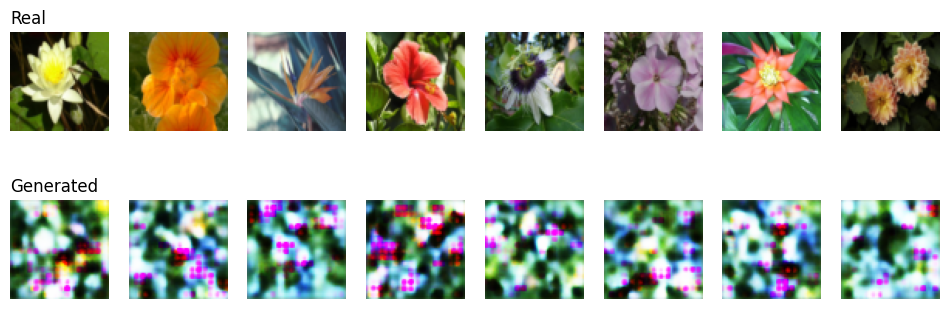

In [33]:
n_samples = 8

# Real images (for comparison)
x, label = next(iter(train_loader))
x = x.to(device)
label = label.to(device)

# Text embedding of the Label
text_emb = text_embedding(label)
text_emb = text_emb.to(device)

# Generated images
z_generated = rev_diff(unet, stride = 20, text_emb = text_emb)
z_generated = z_generated * latent_scale
x_generated = decode_latents(VAE_model, z_generated)

plt.figure(figsize=(12, 4))
for i in range(n_samples):

    # Row 1: real
    plt.subplot(2, n_samples, i+1)
    real_img = (x[i] * 0.5 + 0.5).clamp(0, 1)
    plt.imshow(real_img.cpu().permute(1, 2, 0))
    plt.axis('off')
    if i == 0: plt.title('Real', loc='left')

    # Row 2: generated
    plt.subplot(2, n_samples, i+1+n_samples)
    gen_img = (x_generated[i] * 0.5 + 0.5).clamp(0, 1)
    plt.imshow(gen_img.cpu().permute(1, 2, 0))
    plt.axis('off')
    if i == 0: plt.title('Generated', loc='left')

plt.show()

In [ ]:
# Downloading the trained model

torch.save({
    'unet':         unet.state_dict(),
    'time_emb':     time_emb_object.state_dict(),    # trained too, so it must be saved
    'vae':          VAE_model.state_dict(),          # needed to decode latents back to images
    'latent_scale': latent_scale,                    # the number from the scaling step
    'optimizer':    optimizer.state_dict(),          # only needed if you want to resume training
}, 'ldm_flowers.pth')

from google.colab import files
files.download('ldm_flowers.pth')